---
title: "The next four weeks, October-December 2023"
subtitle: "Weekly subseasonal rainfall forecasts for Indonesia at 0.05°, from GEFSv12 issued every Wednesday and calibrated with CCA and PCR through CPT"
description: "Forecast total rainfall for weeks 1, 2, 3 and 4 and for weeks 3-4 after each Wednesday in late 2023, using GEFSv12 calibrated with CCA and PCR against daily CHIRPS v3.0 at its native 0.05° grid, and measure skill by lead over 2000-2018."
execute:
  enabled: false
---

A weekly subseasonal outlook is issued on one day and covers the weeks after it.
Here it is issued every **Wednesday**, from the GEFSv12 run started at 00 UTC that
day, and gives the **total rainfall** of:

- **week 1** (days 1-7 after the issue date), **week 2** (days 8-14),
  **week 3** (days 15-21) and **week 4** (days 22-28);
- **weeks 3-4** together (days 15-28), the period of NOAA CPC's week 3-4 outlook.

The forecasts are calibrated with CCA and PCR through CPT against **daily CHIRPS
v3.0 at its native 0.05° grid**, about 61,000 pixels over Indonesia, instead of the
0.25° cells of the other cases. The design (issue rule, leads, years, settings,
scores) was fixed before any skill was computed.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine; daily CHIRPS v3.0 for Indonesia
as yearly NetCDF files (made from the Earth Engine export by the tutorial's
`gee_daily_to_netcdf.py`, about 125 MB a year); and internet access the first
time for about 320 GEFSv12 files from the IRI Data Library, no key needed. At
0.05° one CPT fit takes over an hour, so the ten fits run in parallel, one process
each, and need about 10 free CPU cores and 25 GB of disk.
:::

## 1. Issue dates, leads and training targets

GEFSv12's hindcasts (2000-2018) start on **Wednesdays**, the same weekday as the
issue date, so training and real time use exactly the same leads: there is no
offset to bridge, unlike the dekad case. A week 5 would need model day 35, beyond
the run.

The training **targets** are every 7-day window (14-day for weeks 3-4) that
starts on a Thursday in October-December 2000-2018. For each target and lead there
is exactly one Wednesday start, so all five leads are trained and scored on the
same targets. 2023 follows the same rule with GEFSv12's real-time runs. The design
comes from the tutorial's
[weekly GEFS download script](https://github.com/bennyistanto/pycpt-tutorial/blob/main/research/scripts/download_gefs_weeks.py),
which the cell imports so the two cannot disagree.

In [1]:
from pathlib import Path
import datetime as dt
import gzip
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "research/scripts"))
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
import download_gefs_dekads as gefs_source      # request, check and download helpers
import download_gefs_weeks as weeks             # the weekly design
import weekly_fits                              # parallel CPT fits
figures.use_style()

case_root = Path.home() / "PyCPT" / "indonesia-ond-2023-weeks"
daily_dir = Path("/mnt/e/temp/chirps/daily-idn")
leads = list(weeks.LEADS)                        # week1, week2, week3, week4, week34
lead_names = weeks.LEAD_NAMES
training_years = list(weeks.TRAINING_YEARS)
settings = dict(x_eof_modes=(3, 3), validation="CROSSVALIDATION", crossvalidation_window=27,
                synchronous_predictors=True, transform_predictand=None, tailoring=None,
                drymask_threshold=None, skillmask_threshold=None)
cca_settings = dict(settings, y_eof_modes=(3, 3), cca_modes=(2, 2))
workers = 10

design = pd.DataFrame(weeks.design())
for c in ["target", "end", "start"]:
    design[c] = pd.to_datetime(design[c])
per_year = design[(design.kind == "hindcast") & (design.lead == "week1")].groupby("year").size()
print(f"Training targets per year: {per_year.min()}-{per_year.max()}; "
      f"{design[design.kind == 'hindcast'].start.nunique()} hindcast starts, "
      f"{design[design.kind == 'forecast'].start.nunique()} real-time starts in 2023")
(design.groupby(["kind", "lead"])
 .agg(targets=("target", "size"), first_model_day=("first_day", "min"), days=("days", "max"), latest_model_day=("last_day", "max"))
 .rename(index=lead_names, level=1))

Training targets per year: 13-14; 306 hindcast starts, 16 real-time starts in 2023


targets  first_model_day  days  latest_model_day
kind     lead                                                       
forecast Week 1          13                1     7                 7
         Week 2          13                8     7                14
         Week 3          13               15     7                21
         Weeks 3-4       13               15    14                28
         Week 4          13               22     7                28
hindcast Week 1         249                1     7                 7
         Week 2         249                8     7                14
         Week 3         249               15     7                21
         Weeks 3-4      249               15    14                28
         Week 4         249               22     7                28

## 2. Observations: daily CHIRPS v3.0 at 0.05°

The daily files hold one field per UTC day (day D covers 00 UTC D to 00 UTC D+1),
which is how GEFSv12 counts its model days too: model day d after a 00 UTC start
covers the same 24 hours as observed day start + d. A target's total is the sum of
its 7 (or 14) days.

The cell after next checks that these daily values are the CHIRPS v3.0 used
elsewhere in the tutorial: their sums over three dekads should equal the dekadal
archive.

In [2]:
years = sorted(set(design.year) | set(design.year + 1))
files = [daily_dir / f"chirps3_rnl_daily_idn_{y}.nc" for y in years]
assert all(f.exists() for f in files), [f.name for f in files if not f.exists()]
start = time.monotonic()
source = xr.open_mfdataset(files, combine="by_coords")
print("Attributes:", {k: source.precip.attrs[k] for k in ("units", "long_name")})
daily = source.precip.sel(time=source.time.dt.month.isin([10, 11, 12, 1])).load()
print(f"Read {dict(daily.sizes)} (October-January of {years[0]}-{years[-1]}) in {time.monotonic() - start:.0f} s; "
      f"negative values: {int((daily < 0).sum())}")

Attributes: {'units': 'mm/day', 'long_name': 'CHIRPS v3.0 daily precipitation (rnl)'}


Read {'time': 2706, 'lat': 381, 'lon': 961} (October-January of 2000-2024) in 72 s; negative values: 0


The predictand is every 0.05° pixel whose centre lies inside Indonesia (Natural
Earth 1:10m), with data in all training targets. No averaging to cells: this case
keeps the native grid.

In [3]:
records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(daily.lon, daily.lat)
country = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("lat", "lon"), coords={"lat": daily.lat, "lon": daily.lon})


def window_totals(rows):
    out = []
    for r in rows.itertuples():
        days = daily.sel(time=slice(r.target, r.end - pd.Timedelta(days=1)))
        assert days.sizes["time"] == r.days, (r.target, days.sizes["time"])      # every day of the window is present
        out.append(days.sum("time", skipna=False).assign_coords(T=r.target))
    return xr.concat(out, "T").rename({"lat": "Y", "lon": "X"}).sortby("Y", ascending=False)


targets = {days: design[design.lead == ("week1" if days == 7 else "week34")].sort_values("target").reset_index(drop=True)
           for days in (7, 14)}
for lead in leads:                               # every lead uses the same target dates
    assert (design[design.lead == lead].sort_values("target").target.values == targets[7].target.values).all()
start = time.monotonic()
obs = {days: window_totals(t) for days, t in targets.items()}
train = {days: (t.kind == "hindcast").values for days, t in targets.items()}
mask = country.rename({"lat": "Y", "lon": "X"}).sortby("Y", ascending=False)
for days in (7, 14):
    mask = mask & obs[days].isel(T=train[days]).notnull().all("T")
print(f"Window totals built in {time.monotonic() - start:.0f} s: 7-day {dict(obs[7].sizes)}, 14-day {dict(obs[14].sizes)}")
print(f"Pixels inside Indonesia: {int(country.sum()):,}; with data in every training target: {int(mask.sum()):,}")
weights = np.cos(np.deg2rad(mask["Y"])) * mask

dekads = xr.open_dataset("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
for first in ["2005-10-01", "2012-11-11", "2023-12-21"]:
    b = pd.DatetimeIndex(dekads.time_bnds.sel(time=first).values)
    from_daily = daily.sel(time=slice(b[0], b[1] - pd.Timedelta(days=1))).sum("time", skipna=False)
    stored = dekads.precip.sel(time=first).reindex(lat=daily.lat, lon=daily.lon, method="nearest", tolerance=1e-3).load()
    gap = abs(from_daily - stored).where(country)
    differ = from_daily.isnull() != stored.isnull()
    print(f"dekad {b[0]:%d %b %Y} ({(b[1] - b[0]).days} days), Indonesian pixels: largest |daily sum - dekad| {float(gap.max()):.4f} mm, "
          f"same missing pixels: {not bool((differ & country).any())}; pixels outside Indonesia missing only in the daily export: "
          f"{int((differ & ~country).sum())}")

Window totals built in 5 s: 7-day {'T': 262, 'Y': 381, 'X': 961}, 14-day {'T': 262, 'Y': 381, 'X': 961}
Pixels inside Indonesia: 61,192; with data in every training target: 61,190


dekad 01 Oct 2005 (10 days), Indonesian pixels: largest |daily sum - dekad| 0.0001 mm, same missing pixels: True; pixels outside Indonesia missing only in the daily export: 129


dekad 11 Nov 2012 (10 days), Indonesian pixels: largest |daily sum - dekad| 0.0001 mm, same missing pixels: True; pixels outside Indonesia missing only in the daily export: 129


dekad 21 Dec 2023 (11 days), Indonesian pixels: largest |daily sum - dekad| 0.0001 mm, same missing pixels: True; pixels outside Indonesia missing only in the daily export: 129


## 3. Model: daily GEFSv12 to weekly totals

Each start is one request to the IRI Data Library for the predictor box
85-155°E, 20°S-20°N, all members and daily slots; files already on disk are reused
when they cover every model day their targets need (most were downloaded for the
dekad case). Hindcasts store each day's amount (kg m⁻², which is mm), real-time
forecasts a rate (kg m⁻² s⁻¹), converted with 86,400 seconds per day. Model day d
after the start is slot L = d + 0.5. A weekly total is the sum of the target's days,
then the mean over members.

In [4]:
raw_dir = case_root.parent / "indonesia-ond-2023-dekads" / "gefs"
need = weeks.needed_starts()
fetched = sum(gefs_source.ensure(raw_dir, kind, s, last_day) > 0 for (kind, s), last_day in need.items())
print(f"{len(need)} starts checked; downloaded now: {fetched}")

factor = {"hindcast": 1.0, "forecast": 86400.0}
totals, missing, negative = {}, 0, 0
for (kind, s), rows in design.groupby(["kind", "start"]):
    with xr.open_dataset(gefs_source.path_for(raw_dir, kind, s.date()), decode_timedelta=False) as ds:
        pr = ds["pr"].isel(S=0, drop=True).load()
    for r in rows.itertuples():
        d = pr.sel(L=np.arange(r.first_day, r.first_day + r.days) + 0.5)
        missing += int((~np.isfinite(d)).sum())
        negative += int((d < 0).sum())
        totals[r.lead, r.target] = (d * factor[kind]).sum("L", skipna=False).mean("M", skipna=False)
assert missing == 0 and negative == 0
gefs = {lead: xr.concat([totals[lead, t] for t in targets[14 if lead == "week34" else 7].target], "T")
        .assign_coords(T=targets[7].target.values).sortby("Y", ascending=False) for lead in leads}
print(f"GEFS totals per lead {dict(gefs['week1'].sizes)}; missing values {missing}, negative values {negative}")

322 starts checked; downloaded now: 0


GEFS totals per lead {'T': 262, 'Y': 41, 'X': 71}; missing values 0, negative values 0


## 4. Anomalies, and what CPT needs

Rainfall rises through October-December, so model and observations are turned into
**anomalies** from a mean for the same part of the season. A target's mean is the
average of 19 training targets of the same lead, **one from each year 2000-2018:
the one starting closest to the same day of the season** (counted from 1 October).
For each training target the 19 include its own year. The same rule is applied to
model and observations, and to the 2023 targets, whose observed mean is added back
to give a forecast **total**.

Leaving a target's own year out of its mean would change each anomaly by a small
amount; that effect was not measured here.

CPT needs the same three adjustments as in the dekad case: placeholder annual dates
in the original order (cross-validation depends only on the order), the field name
`anomaly` (CPT refuses negative values under precipitation names), and latitudes
from north to south. The cross-validation window of 27 leaves out the held-out
target and 13 on each side, about a whole season, so a training fit never sees
another week of the same season.

In [5]:
def season_day(t):
    t = pd.Timestamp(t)
    return (t - pd.Timestamp(t.year, 10, 1)).days


def climatology_weights(target_dates, train_dates):
    # One row per target: weight 1/19 on the training target of each year starting closest in season day
    train_dates = pd.DatetimeIndex(train_dates)
    by_year = {y: np.flatnonzero(train_dates.year == y) for y in training_years}
    W = np.zeros((len(target_dates), len(train_dates)))
    for i, t in enumerate(target_dates):
        for y, idx in by_year.items():
            k = idx[np.argmin([abs(season_day(train_dates[j]) - season_day(t)) for j in idx])]
            W[i, k] = 1 / len(by_year)
    return W


def apply_weights(W, field, train_mask):
    a = field.isel(T=train_mask).transpose("T", ...).values
    flat = a.reshape(a.shape[0], -1)
    clim = (W @ np.nan_to_num(flat)).reshape((W.shape[0],) + a.shape[1:])
    return field.copy(data=clim.astype("float32"))


all_T = targets[7].target.values
W = climatology_weights(all_T, all_T[train[7]])
assert np.allclose(W.sum(1), 1) and ((W > 0).sum(1) == 19).all()
y_clim = {days: apply_weights(W, obs[days], train[days]).where(mask) for days in (7, 14)}
y_anom = {days: (obs[days] - y_clim[days]).where(mask) for days in (7, 14)}
x_anom = {lead: gefs[lead] - apply_weights(W, gefs[lead], train[7]) for lead in leads}
days_of = {lead: 14 if lead == "week34" else 7 for lead in leads}
train_T = all_T[train[7]]
distance = [abs(season_day(t) - season_day(train_T[j])) for i, t in enumerate(all_T) for j in np.flatnonzero(W[i])]
print(f"Every mean averages 19 targets, one per year; their start differs from the target's season day by "
      f"{np.mean(distance):.1f} days on average, at most {max(distance)} days")
area = lambda f: float(f.where(mask).weighted(weights).mean(("Y", "X")))
print(f"2000-2018 mean of all training targets, Indonesian pixels: 7-day {area(obs[7].isel(T=train[7]).mean('T')):.1f} mm, "
      f"14-day {area(obs[14].isel(T=train[14]).mean('T')):.1f} mm")


def cpt_ready(a, first_year):
    years = first_year + np.arange(a.sizes["T"])
    a = a.drop_vars([c for c in a.coords if c not in ("T", "Y", "X")]).transpose("T", "Y", "X")
    a = a.assign_coords(T=pd.to_datetime([f"{y}-10-04" for y in years]),
                        Ti=("T", pd.to_datetime([f"{y}-10-01" for y in years])),
                        Tf=("T", pd.to_datetime([f"{y}-10-07" for y in years])))
    a = a.rename("anomaly")
    a.attrs = {"units": "mm", "missing": -999.0}
    return a


inputs_dir = case_root / "inputs"
inputs_dir.mkdir(parents=True, exist_ok=True)
paths = {}
for days in (7, 14):
    paths["Y", days] = inputs_dir / f"Y-{days}day.nc"
    cpt_ready(y_anom[days].isel(T=train[days]), 1701).to_netcdf(paths["Y", days])
for lead in leads:
    paths["X", lead] = inputs_dir / f"X-{lead}.nc"
    paths["F", lead] = inputs_dir / f"F-{lead}.nc"
    cpt_ready(x_anom[lead].isel(T=train[7]), 1701).to_netcdf(paths["X", lead])
    cpt_ready(x_anom[lead].isel(T=~train[7]), 1990).to_netcdf(paths["F", lead])
print({f"{k[0]}-{k[1]}": f"{p.stat().st_size / 1e6:.0f} MB" for k, p in paths.items()})

Every mean averages 19 targets, one per year; their start differs from the target's season day by 1.7 days on average, at most 6 days


2000-2018 mean of all training targets, Indonesian pixels: 7-day 64.1 mm, 14-day 129.2 mm


{'Y-7': '365 MB', 'Y-14': '365 MB', 'X-week1': '3 MB', 'F-week1': '0 MB', 'X-week2': '3 MB', 'F-week2': '0 MB', 'X-week3': '3 MB', 'F-week3': '0 MB', 'X-week4': '3 MB', 'F-week4': '0 MB', 'X-week34': '3 MB', 'F-week34': '0 MB'}


## 5. Ten fits, in parallel

CCA (3 predictor and 3 predictand EOFs, 2 CCA modes) and PCR (3 predictor EOFs) for
each of the five leads, through `cptcore`, the layer PyCPT's `evaluate_models`
calls. Each fit runs in its own process (`weekly_fits.py` in the tutorial's
research scripts) and keeps only the forecast and skill maps; a fit is reused only
if its saved result was made from byte-identical inputs and settings. Each worker
also recomputes the correlation from CPT's own cross-validated hindcasts and stores
the largest difference from CPT's map.

In [6]:
jobs = [dict(lead=lead, method=method, folder=str(case_root / f"fit-{lead}-{method.lower()}"),
             inputs={"X": str(paths["X", lead]), "Y": str(paths["Y", days_of[lead]]), "F": str(paths["F", lead])},
             settings=cca_settings if method == "CCA" else settings)
        for lead in leads for method in ["CCA", "PCR"]]
start = time.monotonic()
done = weekly_fits.run_all(jobs, workers=workers)
print(f"All fits finished in {(time.monotonic() - start) / 60:.0f} min wall time")
results, rows = {}, []
for d in done:
    r = xr.open_dataset(d["path"]).load()
    results[d["lead"], d["method"]] = r
    rows.append({"lead": lead_names[d["lead"]], "method": d["method"], "fit (min)": round(r.attrs["fit_seconds"] / 60, 1),
                 "reused": d["reused"], "hindcast values below 0 (%)": round(r.attrs["hindcast_values_below_zero_percent"], 1),
                 "largest gap, CPT vs recomputed correlation": r.attrs["largest_gap_cpt_vs_recomputed_pearson"]})
pd.DataFrame(rows).set_index(["lead", "method"])

All fits finished in 0 min wall time


fit (min)  reused  hindcast values below 0 (%)  \
lead      method                                                   
Week 1    CCA          75.8    True                         52.5   
          PCR          23.2    True                         52.2   
Week 2    CCA          75.5    True                         51.2   
          PCR          23.8    True                         51.0   
Week 3    CCA          90.1    True                         50.7   
          PCR          25.5    True                         51.1   
Week 4    CCA          88.3    True                         50.6   
          PCR          25.6    True                         51.4   
Weeks 3-4 CCA          89.8    True                         50.4   
          PCR          23.5    True                         50.8   

                  largest gap, CPT vs recomputed correlation  
lead      method                                              
Week 1    CCA                                   8.070593e-07  
          PCR                                   8.593387e-07  
Week 2    CCA                                   7.515310e-07  
          PCR                                   7.595288e-07  
Week 3    CCA                                   8.418476e-07  
          PCR                                   8.168529e-07  
Week 4    CCA                                   7.953066e-07  
          PCR                                   7.848229e-07  
Weeks 3-4 CCA                                   8.175549e-07  
          PCR                                   8.244951e-07

Negative hindcast values show the anomalies were not clipped at zero, and a gap near
zero shows CPT's correlation map is the correlation of its own cross-validated
hindcasts.

## 6. Skill by lead

Cross-validated scores over the 249 training targets, as area-weighted means over
the Indonesian pixels (weights: cosine of latitude):

- **Pearson correlation** of hindcast and observed anomalies; 0 is no linear relationship.
- **2AFC**: the chance (in %) that the hindcasts rank two different targets in the observed order; 50% is no skill.
- **ROC area** for below- and above-normal weeks; 0.5 is no skill.

The **raw GEFS** baseline is the model's own anomaly, interpolated linearly from 1°
to the pixel centres, correlated with the observed anomalies. It involves no
fitting, so it pays none of the cost that cross-validation charges the calibrated
forecasts.

In [7]:
def clean(a):
    return a.where(a > -999).reindex(Y=mask["Y"], X=mask["X"], method="nearest", tolerance=1e-4).where(mask)


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


raw_pearson = {}
for lead in leads:
    xa = x_anom[lead].isel(T=train[7]).interp(Y=mask["Y"], X=mask["X"], method="linear")
    raw_pearson[lead] = pearson(xa, y_anom[days_of[lead]].isel(T=train[7])).where(mask)

rows = []
for (lead, method), r in results.items():
    rows.append({"lead": lead, "name": lead_names[lead], "method": method,
                 "Pearson": area(clean(r.skill_pearson)), "2AFC (%)": area(clean(r.skill_two_alternative_forced_choice)),
                 "ROC below normal": area(clean(r.skill_roc_area_below_normal)), "ROC above normal": area(clean(r.skill_roc_area_above_normal))})
for lead in leads:
    rows.append({"lead": lead, "name": lead_names[lead], "method": "raw GEFS", "Pearson": area(raw_pearson[lead])})
order = {lead: i for i, lead in enumerate(leads)}
skill_by_lead = (pd.DataFrame(rows).assign(o=lambda d: d.lead.map(order)).sort_values(["o", "method"]).drop(columns="o")
                 .set_index(["lead", "method"]))
skill_by_lead.round(3)

name  Pearson  2AFC (%)  ROC below normal  \
lead   method                                                     
week1  CCA          Week 1    0.351    62.760             0.693   
       PCR          Week 1    0.356    63.056             0.696   
       raw GEFS     Week 1    0.501       NaN               NaN   
week2  CCA          Week 2    0.287    60.317             0.658   
       PCR          Week 2    0.284    60.317             0.658   
       raw GEFS     Week 2    0.336       NaN               NaN   
week3  CCA          Week 3    0.265    59.562             0.650   
       PCR          Week 3    0.264    59.583             0.649   
       raw GEFS     Week 3    0.254       NaN               NaN   
week4  CCA          Week 4    0.170    56.717             0.611   
       PCR          Week 4    0.176    56.758             0.609   
       raw GEFS     Week 4    0.175       NaN               NaN   
week34 CCA       Weeks 3-4    0.262    59.632             0.653   
       PCR       Weeks 3-4    0.264    59.692             0.653   
       raw GEFS  Weeks 3-4    0.255       NaN               NaN   

                 ROC above normal  
lead   method                      
week1  CCA                  0.672  
       PCR                  0.678  
       raw GEFS               NaN  
week2  CCA                  0.639  
       PCR                  0.639  
       raw GEFS               NaN  
week3  CCA                  0.628  
       PCR                  0.629  
       raw GEFS               NaN  
week4  CCA                  0.586  
       PCR                  0.589  
       raw GEFS               NaN  
week34 CCA                  0.624  
       PCR                  0.628  
       raw GEFS               NaN

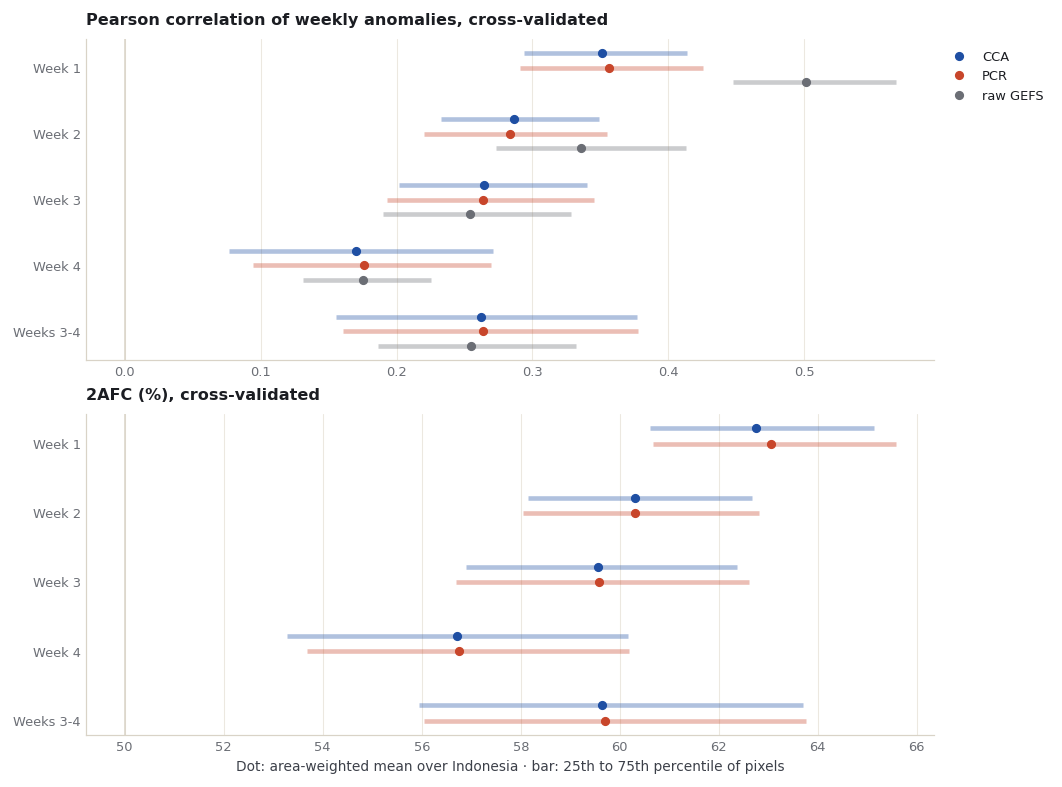

In [8]:
def quartiles(field):
    return np.nanpercentile(field.where(mask).values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw GEFS": figures.MUTED}
panels = [("Pearson", "skill_pearson", "Pearson correlation of weekly anomalies, cross-validated", 0),
          ("2AFC (%)", "skill_two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 7.0), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw GEFS" and column != "Pearson":
            continue
        offset = (k - 1) * 0.22
        for i, lead in enumerate(leads):
            field = raw_pearson[lead] if method == "raw GEFS" else clean(results[lead, method][metric])
            low, high = quartiles(field)
            ax.plot([low, high], [i + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], i + offset, "o", color=colour, markersize=5,
                    label=method if i == 0 else None)
    ax.set_yticks(range(len(leads)), [lead_names[lead] for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of pixels")
assets = repo / "docs/assets/week-leads-2023"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "skill-by-lead.png")
plt.show()

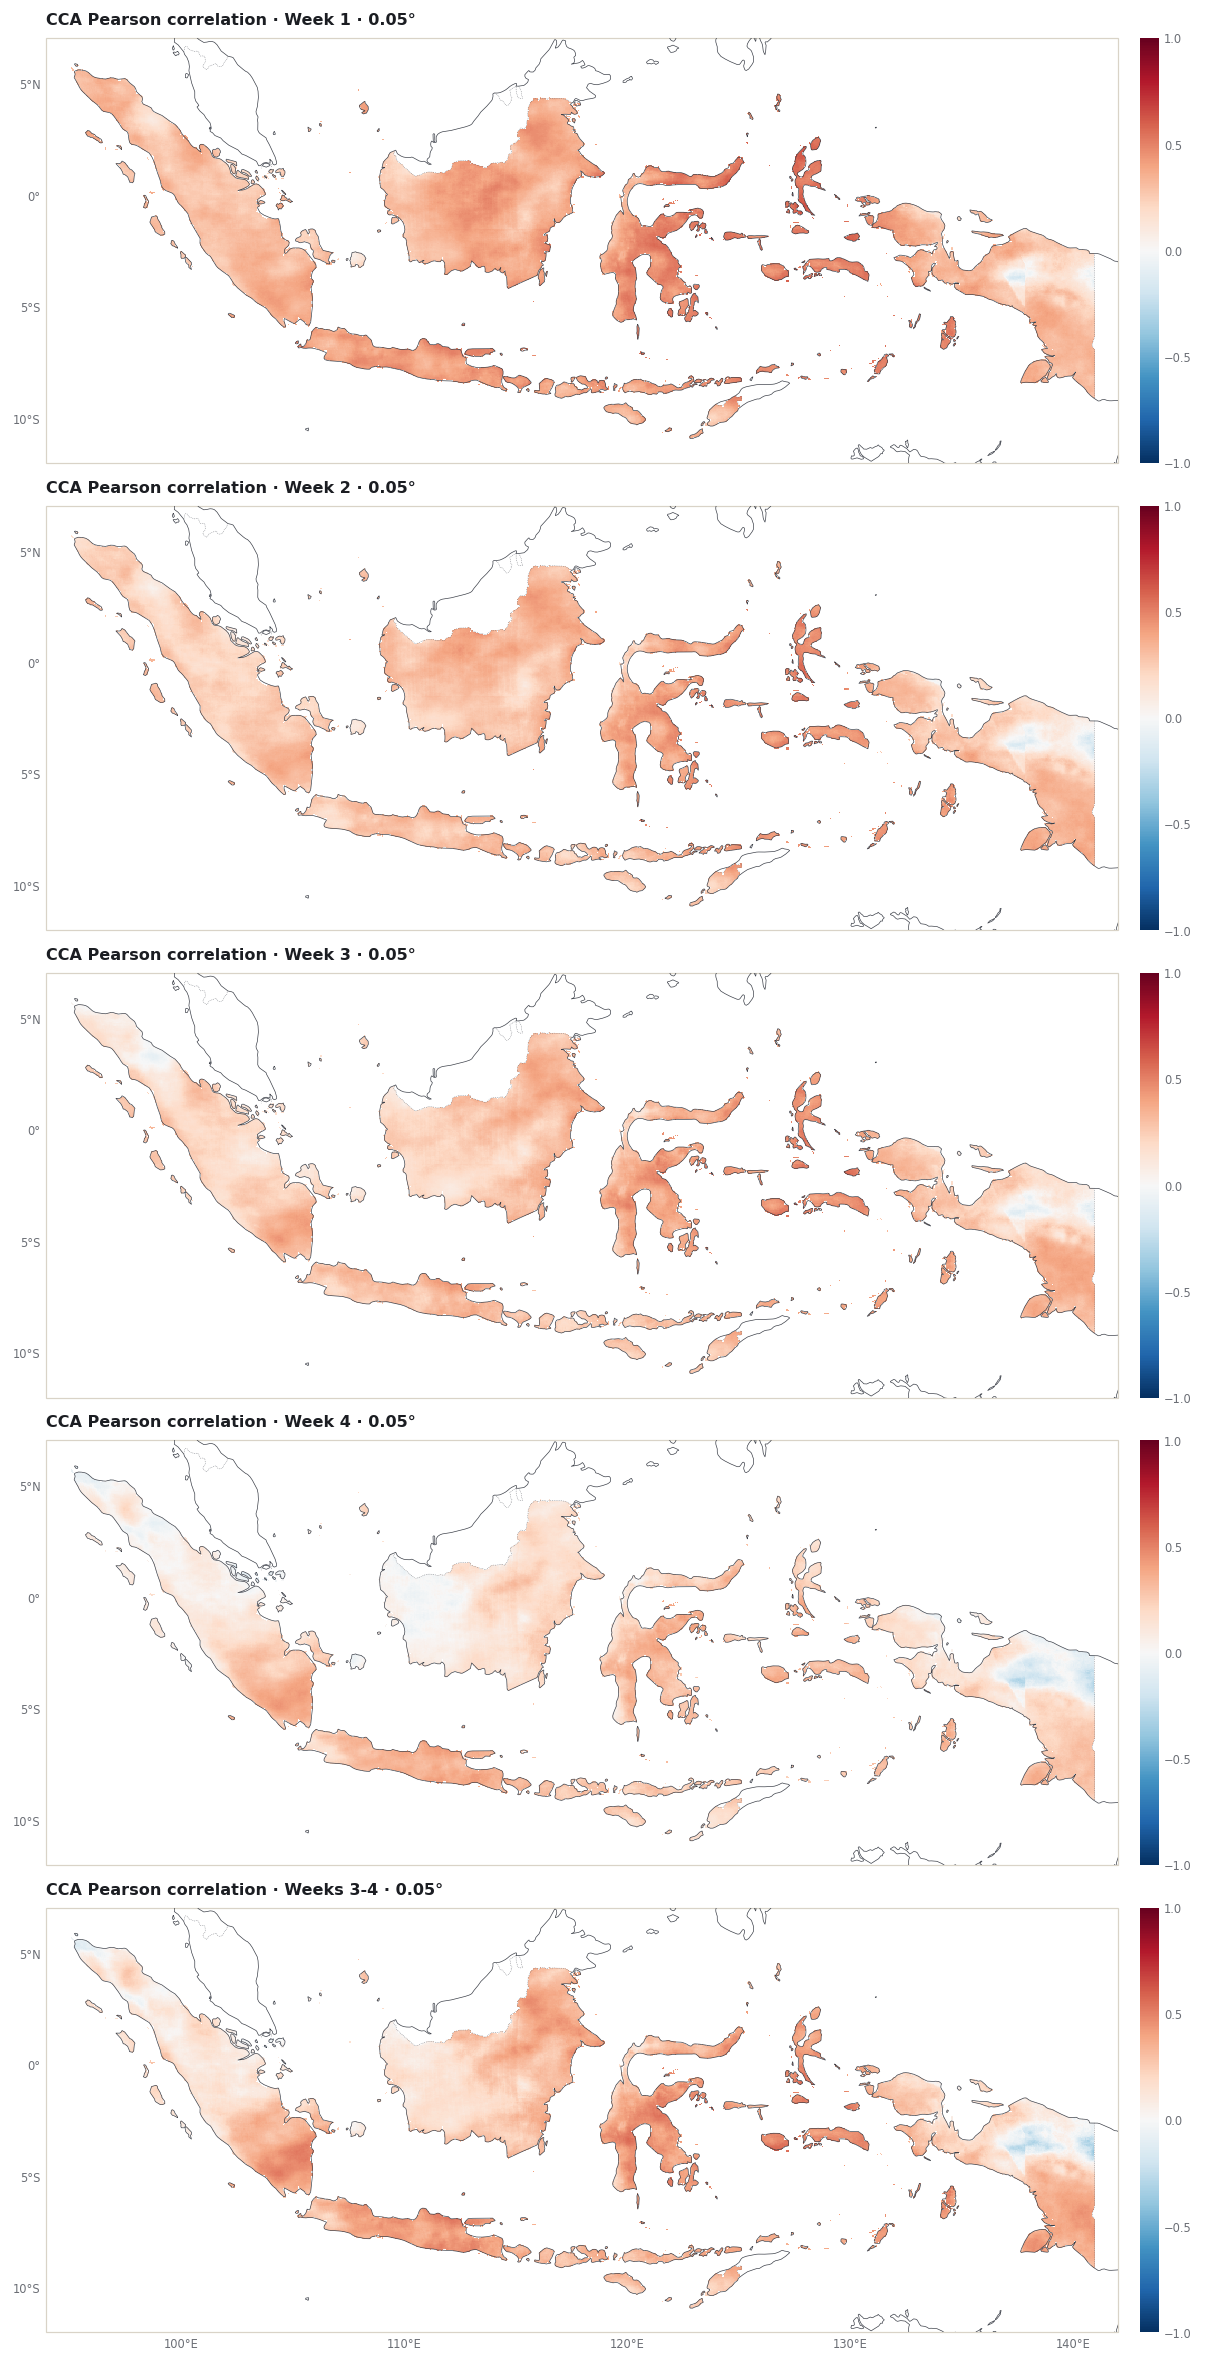

In [9]:
box = {"west": float(mask.X.min()) - .025, "east": float(mask.X.max()) + .025, "south": float(mask.Y.min()) - .025, "north": float(mask.Y.max()) + .025}
predictand_box = figures.extent_of(box)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, clean(results[lead, "CCA"].skill_pearson), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · {lead_names[lead]} · 0.05°")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 7. The 2023 forecasts, as issued

Each Wednesday from late September to late December 2023 gives a forecast for the
weeks after it. A forecast **total** is the target's observed 2000-2018 mean (the
rule of section 4) plus the calibrated anomaly; where that sum is negative it is set
to zero, and the cell counts how often.

CPT also gives tercile probabilities. It defines the categories from the training
samples it was given, all 249 targets together, so the observed category uses the
same definition: at each pixel, below the 33rd or above the 67th percentile of the
249 training anomalies (NumPy's `hazen` rule, as in
[chapter 5](../learn/05-probabilistic-forecasts.ipynb)).

In [10]:
test_T = all_T[~train[7]]
observed, observed_anom, clim_2023, category = {}, {}, {}, {}
for days in (7, 14):
    observed[days] = obs[days].isel(T=~train[days]).where(mask)
    clim_2023[days] = y_clim[days].isel(T=~train[days])
    observed_anom[days] = y_anom[days].isel(T=~train[days])
    lo, hi = np.quantile(y_anom[days].isel(T=train[days]).values, [0.33, 0.67], axis=0, method="hazen")
    lower = xr.DataArray(lo, coords={"Y": mask["Y"], "X": mask["X"]}, dims=("Y", "X"))
    upper = lower.copy(data=hi)
    a = observed_anom[days]
    category[days] = xr.where(a < lower, 0, xr.where(a > upper, 2, 1)).where(a.notnull())

forecast, clipped = {}, {}
for (lead, method), r in results.items():
    days = days_of[lead]
    anomaly = clean(r.deterministic).assign_coords(T=test_T)
    total = clim_2023[days] + anomaly
    clipped[lead, method] = int((total < 0).sum())
    probability = clean(r.probabilistic).assign_coords(T=test_T)
    most_likely = probability.fillna(-1).argmax("C").where(probability.notnull().all("C") & mask)
    forecast[lead, method] = dict(total=total.clip(min=0).where(mask), probability=probability, most_likely=most_likely,
                                  top=probability.max("C").where(mask))
print("Forecast totals below zero before clipping (pixel-targets):", {f"{lead}-{m}": n for (lead, m), n in clipped.items()},
      f"of {int(mask.sum()) * len(test_T):,} per lead")

issues = {}
for r in design[design.kind == "forecast"].sort_values(["start", "first_day"]).itertuples():
    issues.setdefault(r.start, []).append((r.lead, r.target))
print(f"{len(issues)} Wednesdays in 2023 with at least one target; complete issues (all five leads): "
      f"{sum(len(v) == len(leads) for v in issues.values())}")
for s, items in list(issues.items())[:3]:
    print(f"  issued {s:%a %d %b}: " + ", ".join(f"{lead_names[lead]} from {t:%d %b}" for lead, t in items))

Forecast totals below zero before clipping (pixel-targets): {'week1-CCA': 4627, 'week1-PCR': 9415, 'week2-CCA': 3669, 'week2-PCR': 9615, 'week3-CCA': 3024, 'week3-PCR': 4970, 'week4-CCA': 3597, 'week4-PCR': 4534, 'week34-CCA': 2418, 'week34-PCR': 3662} of 795,470 per lead
16 Wednesdays in 2023 with at least one target; complete issues (all five leads): 10
  issued Wed 13 Sep: Week 4 from 05 Oct
  issued Wed 20 Sep: Week 3 from 05 Oct, Weeks 3-4 from 05 Oct, Week 4 from 12 Oct
  issued Wed 27 Sep: Week 2 from 05 Oct, Week 3 from 12 Oct, Weeks 3-4 from 12 Oct, Week 4 from 19 Oct


One issue date in full: the forecast issued on **Wednesday 1 November 2023** (the
issue date of the monthly and seasonal cases) for each lead, with the observation
below each forecast. One column.

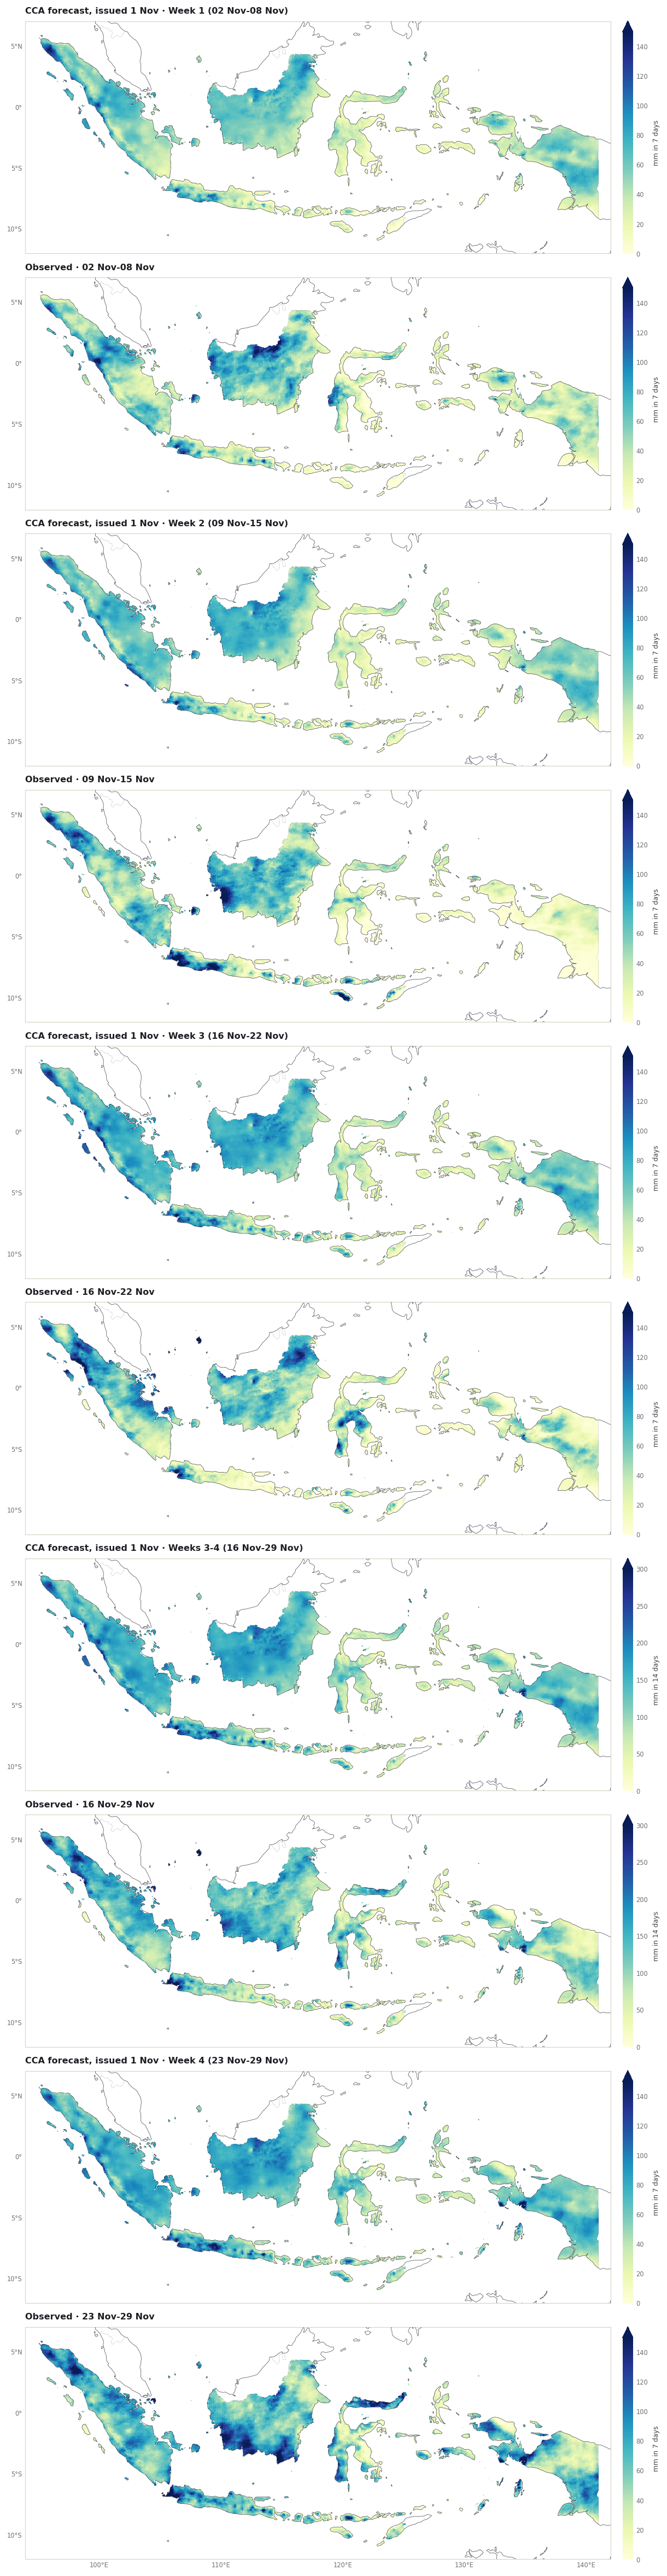

In [11]:
example = pd.Timestamp("2023-11-01")
fig, grid = figures.stacked([figures.map_height(predictand_box)] * (2 * len(leads)))
row = 0
for lead, target in issues[example]:
    days = days_of[lead]
    end = target + pd.Timedelta(days=days - 1)
    vmax = 150 if days == 7 else 300
    for label, field in [(f"CCA forecast, issued 1 Nov · {lead_names[lead]} ({target:%d %b}-{end:%d %b})", forecast[lead, "CCA"]["total"].sel(T=target)),
                         (f"Observed · {target:%d %b}-{end:%d %b}", observed[days].sel(T=target))]:
        ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == 2 * len(leads) - 1)
        image = figures.draw_field(ax, field, cmap="YlGnBu", vmin=0, vmax=vmax)
        ax.set_title(label)
        figures.colorbar(fig, image, ax, f"mm in {days} days", extend="max")
        row += 1
fig.savefig(assets / "issued-2023-11-01.png")
plt.show()

Over all 13 targets of 2023, for each lead: the area-weighted forecast total against
the observed total, then scores over every pixel and target (area-weighted):

- **Hit rate**: share where the most likely category was the one observed. The
  **reference** is the share of the most frequent observed category.
- **RPSS 2023**: ranked probability skill score against climatological odds
  (33/34/33%); above 0 is closer to what happened. Thirteen weeks of one season, not
  a skill estimate.
- **RMSE 2023**: error of the forecast totals in mm.

In [12]:
def rps(probability, cat):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(cat <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


rows, references = [], {}
for days in (7, 14):
    w3 = (weights * category[days].notnull()).astype(float)
    references[days] = {name: float(w3.where(category[days] == k, 0).sum() / w3.sum() * 100)
                        for k, name in enumerate(["below normal", "near normal", "above normal"])}
for (lead, method), f in forecast.items():
    days = days_of[lead]
    w = (weights * category[days].notnull()).where(f["most_likely"].notnull(), 0).astype(float)
    climatology = xr.DataArray([33.0, 34.0, 33.0], dims="C", coords={"C": f["probability"]["C"]}).broadcast_like(f["probability"])
    rows.append({"lead": lead, "name": lead_names[lead], "method": method,
                 "hit rate (%)": float(w.where(f["most_likely"] == category[days], 0).sum() / w.sum() * 100),
                 "reference hit rate (%)": max(references[days].values()),
                 "RPSS 2023": float(1 - rps(f["probability"], category[days]).weighted(w).mean()
                                    / rps(climatology, category[days]).weighted(w).mean()),
                 "RMSE 2023 (mm)": float(np.sqrt(((f["total"] - observed[days]) ** 2).weighted(w).mean())),
                 "mean forecast (mm)": float(f["total"].weighted(w).mean()),
                 "observed mean (mm)": float(observed[days].weighted(w).mean()),
                 **{f"forecast {name} (%)": float(w.where(f["most_likely"] == k, 0).sum() / w.sum() * 100)
                    for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = (pd.DataFrame(rows).assign(o=lambda d: d.lead.map(order)).sort_values(["o", "method"]).drop(columns="o")
                 .set_index(["lead", "method"]))
print("Observed categories, share of area x targets (%):", {d: {k: round(v, 1) for k, v in r.items()} for d, r in references.items()})
forecast_2023.round(2)

Observed categories, share of area x targets (%): {7: {'below normal': 49.3, 'near normal': 32.5, 'above normal': 18.1}, 14: {'below normal': 52.2, 'near normal': 30.7, 'above normal': 17.1}}


name  hit rate (%)  reference hit rate (%)  RPSS 2023  \
lead   method                                                               
week1  CCA        Week 1         50.38                   49.35       0.12   
       PCR        Week 1         49.46                   49.35       0.12   
week2  CCA        Week 2         50.23                   49.35       0.12   
       PCR        Week 2         49.64                   49.35       0.11   
week3  CCA        Week 3         46.81                   49.35       0.07   
       PCR        Week 3         45.87                   49.35       0.07   
week4  CCA        Week 4         45.60                   49.35       0.08   
       PCR        Week 4         44.82                   49.35       0.07   
week34 CCA     Weeks 3-4         53.24                   52.19       0.14   
       PCR     Weeks 3-4         51.09                   52.19       0.13   

               RMSE 2023 (mm)  mean forecast (mm)  observed mean (mm)  \
lead   method                                                           
week1  CCA              28.64               55.71               51.08   
       PCR              28.83               55.65               51.08   
week2  CCA              28.55               55.95               51.08   
       PCR              28.75               55.67               51.08   
week3  CCA              29.66               58.00               51.08   
       PCR              29.74               57.77               51.08   
week4  CCA              29.77               57.77               51.08   
       PCR              29.99               57.71               51.08   
week34 CCA              48.26              117.50              106.47   
       PCR              48.67              117.43              106.47   

               forecast below (%)  forecast near (%)  forecast above (%)  
lead   method                                                             
week1  CCA                  70.80              10.47               18.73  
       PCR                  67.98              11.20               20.82  
week2  CCA                  66.20              13.28               20.52  
       PCR                  64.62              13.35               22.03  
week3  CCA                  58.70              16.16               25.14  
       PCR                  58.40              15.38               26.22  
week4  CCA                  61.44              10.99               27.57  
       PCR                  60.43              10.28               29.30  
week34 CCA                  72.76               9.34               17.89  
       PCR                  70.13               9.44               20.43

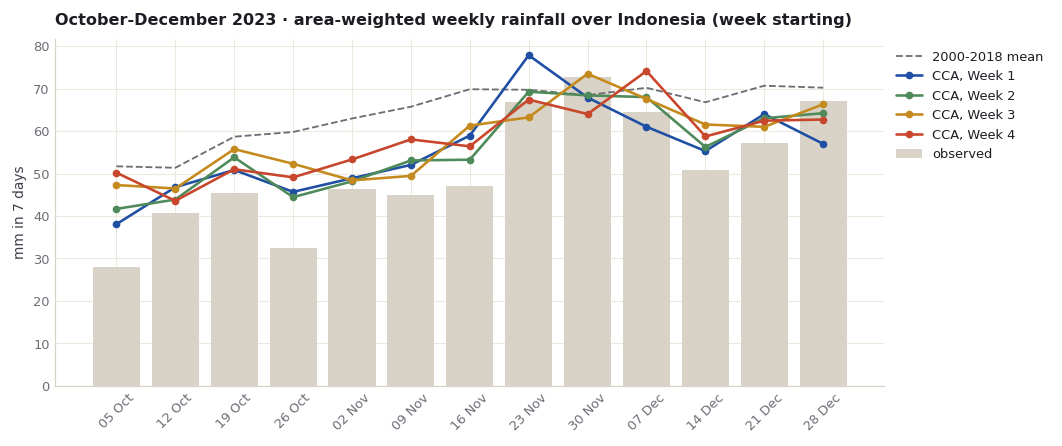

In [13]:
labels = [f"{pd.Timestamp(t):%d %b}" for t in test_T]
observed_series = observed[7].weighted(weights).mean(("Y", "X"))
clim_series = clim_2023[7].weighted(weights).mean(("Y", "X"))
week_leads = ["week1", "week2", "week3", "week4"]
fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 3.9), layout="constrained")
x = np.arange(len(test_T))
ax.bar(x, observed_series, color=figures.LINE, label="observed")
ax.plot(x, clim_series, color=figures.MUTED, linestyle="--", linewidth=1.2, label="2000-2018 mean")
for lead, colour in zip(week_leads, [figures.ACCENT, figures.GREEN, figures.GOLD, figures.MARK]):
    s = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X"))
    ax.plot(x, s, "o-", color=colour, markersize=4, label=f"CCA, {lead_names[lead]}")
ax.set_xticks(x, labels, rotation=45)
ax.set_ylabel("mm in 7 days")
ax.set_title("October-December 2023 · area-weighted weekly rainfall over Indonesia (week starting)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "ond-2023-weekly-series.png")
plt.show()

## 8. Save the results

Tables and figures for the story page, a NetCDF file of the skill maps, and the
fields of the interactive page. At 0.05° every map has about 61,000 values, so the
page reads small binary files, one per map, only when a view needs them: integers
at a stated scale, stored only at the Indonesian pixels in the order of a shared
pixel list, and gzip-compressed.

In [14]:
data_dir = repo / "docs/data/week-leads-2023"
data_dir.mkdir(parents=True, exist_ok=True)
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
forecast_2023.round(4).to_csv(data_dir / "ond-2023-weekly-forecasts.csv")
design.assign(**{c: design[c].dt.date for c in ["target", "end", "start"]}).to_csv(data_dir / "lead-design.csv", index=False)
area_rows = {"week starting": [str(pd.Timestamp(t).date()) for t in test_T], "observed": observed_series.values, "mean_2000_2018": clim_series.values}
for lead in week_leads:
    area_rows[f"cca_total_{lead}"] = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X")).values
pd.DataFrame(area_rows).round(3).to_csv(data_dir / "ond-2023-area-totals.csv", index=False)
summary = {"target": "October-December 2023, weekly", "model": "GEFSv12 (IRI SubX GEFSv12_CPC)", "grid": "CHIRPS v3.0 native 0.05 degree",
           "issue_rule": "issued Wednesday 00 UTC; week 1-4 = days 1-7, 8-14, 15-21, 22-28; weeks 3-4 = days 15-28",
           "training_years": [training_years[0], training_years[-1]], "training_targets_per_lead": int(train[7].sum()),
           "pixels": int(mask.sum()), "cross_validation_window": settings["crossvalidation_window"],
           "settings": {k: str(v) for k, v in cca_settings.items()},
           "observed_category_percent_2023": {f"{d}-day": {k: round(v, 2) for k, v in r.items()} for d, r in references.items()},
           "fit_minutes": {f"{lead}-{m}": round(r.attrs["fit_seconds"] / 60, 1) for (lead, m), r in results.items()},
           "clipped_pixel_targets": {f"{lead}-{m}": n for (lead, m), n in clipped.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset()
for lead in leads:
    for m in ["CCA", "PCR"]:
        maps[f"{m.lower()}_pearson_{lead}"] = clean(results[lead, m].skill_pearson).drop_vars(
            [c for c in results[lead, m].skill_pearson.coords if c not in ("Y", "X")], errors="ignore").astype("float32")
    maps[f"raw_pearson_{lead}"] = raw_pearson[lead].astype("float32")
_ = save_netcdf(maps, data_dir / "week-leads-2023-skill-maps.nc", overwrite=True,
            metadata={"note": "Weekly rainfall, GEFSv12 week 1-4 and weeks 3-4: cross-validated correlation 2000-2018 at 0.05 degree"})

In [15]:
# Interactive fields: one gzip-compressed binary file per map
field_dir = assets / "fields"
field_dir.mkdir(exist_ok=True)
for old in field_dir.glob("*"):
    old.unlink()
north = mask.transpose("Y", "X").values
flat = np.flatnonzero(north.ravel())                          # row 0 = northernmost pixel row
n = len(flat)


def at_pixels(a):
    return np.asarray(a.transpose("Y", "X").values, dtype="float64").ravel()[flat]


def encode(values, kind, scale):
    v = np.round(values * scale)
    if kind == "i16":
        return np.where(np.isfinite(v), np.clip(v, -32767, 32767), -32768).astype("<i2").tobytes()
    if kind == "u16":
        return np.where(np.isfinite(v), np.clip(v, 0, 65534), 65535).astype("<u2").tobytes()
    return np.where(np.isfinite(v), np.clip(v, 0, 254), 255).astype("u1").tobytes()


def write(name, parts):
    blob = b"".join(encode(*p) for p in parts)
    (field_dir / f"{name}.bin.gz").write_bytes(gzip.compress(blob, 9, mtime=0))


(assets / "pixels.bin").write_bytes(flat.astype("<i4").tobytes())
for lead in leads:
    for m in ["CCA", "PCR"]:
        write(f"skill-{m}-pearson-{lead}", [(at_pixels(clean(results[lead, m].skill_pearson)), "i16", 1000)])
        write(f"skill-{m}-twoafc-{lead}", [(at_pixels(clean(results[lead, m].skill_two_alternative_forced_choice)), "i16", 10)])
    write(f"skill-raw-pearson-{lead}", [(at_pixels(raw_pearson[lead]), "i16", 1000)])
for days in (7, 14):
    for t in test_T:
        key = f"{pd.Timestamp(t):%Y-%m-%d}"
        write(f"obs-{days}-{key}", [(at_pixels(observed[days].sel(T=t)), "u16", 10), (at_pixels(clim_2023[days].sel(T=t).where(mask)), "u16", 10),
                                    (at_pixels(category[days].sel(T=t)), "u8", 1)])
for (lead, m), f in forecast.items():
    for t in test_T:
        key = f"{pd.Timestamp(t):%Y-%m-%d}"
        write(f"fc-{lead}-{m}-{key}", [(at_pixels(f["total"].sel(T=t)), "u16", 10), (at_pixels(f["most_likely"].sel(T=t)), "u8", 1),
                                        (at_pixels(f["top"].sel(T=t)), "u8", 1)])


def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]


manifest = {
    "grid": {"west": round(float(mask.X.min()) - .025, 3), "north": round(float(mask.Y.max()) + .025, 3), "step": 0.05,
             "nx": int(mask.sizes["X"]), "ny": int(mask.sizes["Y"]), "pixels": n},
    "leads": list(range(1, len(leads) + 1)), "leadKeys": leads, "leadNames": [lead_names[lead] for lead in leads],
    "days": {lead: days_of[lead] for lead in leads},
    "firstDay": {lead: weeks.LEADS[lead][0] for lead in leads},
    "methods": ["CCA", "PCR"], "rawName": "raw GEFS", "training": "2000-2018",
    "sample": "the 249 training targets of 2000-2018", "cellText": f"Indonesia's {n:,} pixels at 0.05°",
    "layout": {"skill": [["value", "i16"]], "obs": [["total", "u16", 10], ["mean", "u16", 10], ["category", "u8", 1]],
               "fc": [["total", "u16", 10], ["category", "u8", 1], ["probability", "u8", 1]]},
    "scales": {"pearson": 1000, "twoafc": 10},
    "issues": [{"issued": f"{s:%Y-%m-%d}", "label": f"{s:%a %d %b %Y}",
                "targets": [{"lead": lead, "start": f"{t:%Y-%m-%d}", "days": days_of[lead]} for lead, t in items]}
               for s, items in issues.items()],
    "skillTable": records(skill_by_lead.reset_index().rename(columns={"lead": "leadKey"}).assign(
        lead=lambda d: d.leadKey.map(order) + 1).round(4)),
    "scores2023": records(forecast_2023.reset_index().round(3)),
    "series": pd.DataFrame(area_rows).round(2).to_dict(orient="list"),
    "rainMax": {days: float(np.ceil(np.nanpercentile(np.concatenate(
        [observed[days].values.ravel()] + [forecast[lead, m]["total"].values.ravel() for lead in leads for m in ["CCA", "PCR"] if days_of[lead] == days]),
        99) / 50) * 50) for days in (7, 14)},
}
(assets / "manifest.json").write_text(json.dumps(manifest, separators=(",", ":"), allow_nan=False) + "\n")
sizes = sorted(p.stat().st_size for p in field_dir.iterdir())
print(f"{n:,} pixels; {len(sizes)} field files, {sum(sizes) / 1e6:.1f} MB in total (largest {sizes[-1] / 1e3:.0f} kB); "
      f"manifest {(assets / 'manifest.json').stat().st_size / 1e3:.0f} kB")
for f in sorted(data_dir.iterdir()) + sorted(p for p in assets.iterdir() if p.is_file()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

61,190 pixels; 181 field files, 21.5 MB in total (largest 194 kB); manifest 11 kB
docs/data/week-leads-2023/lead-design.csv  (80 kB)
docs/data/week-leads-2023/ond-2023-area-totals.csv  (1 kB)
docs/data/week-leads-2023/ond-2023-weekly-forecasts.csv  (1 kB)
docs/data/week-leads-2023/skill-by-lead.csv  (1 kB)
docs/data/week-leads-2023/summary.json  (2 kB)
docs/data/week-leads-2023/week-leads-2023-skill-maps.nc  (3363 kB)
docs/assets/week-leads-2023/cca-pearson-by-lead.png  (1403 kB)
docs/assets/week-leads-2023/issued-2023-11-01.png  (3231 kB)
docs/assets/week-leads-2023/manifest.json  (11 kB)
docs/assets/week-leads-2023/ond-2023-weekly-series.png  (130 kB)
docs/assets/week-leads-2023/pixels.bin  (245 kB)
docs/assets/week-leads-2023/skill-by-lead.png  (85 kB)


## References {.unnumbered .reference-section}

1. IRI Data Library. *SubX EMC GEFSv12_CPC* (hindcast and forecast precipitation). <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.SubX/.EMC/.GEFSv12_CPC/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
2. Guan, H., Zhu, Y., Sinsky, E., et al. (2022). GEFSv12 reforecast dataset for supporting subseasonal and hydrometeorological applications. *Monthly Weather Review*, 150(3), 647-665. <https://doi.org/10.1175/MWR-D-21-0245.1>
3. NOAA Climate Prediction Center. *Week 3-4 Outlooks* (issued on Fridays; the outlook shown on 11 November 2026 was issued Friday 6 November 2026 for 21 November to 4 December, days 15 to 28 after issue). <https://www.cpc.ncep.noaa.gov/products/predictions/WK34/>
4. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
5. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
6. Climate Hazards Center. *Information about CHIRPS Daily Precipitation* (CHIRPS v3.0 daily readme). <https://data.chc.ucsb.edu/products/CHIRPS/v3.0/daily/readme.txt>
7. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
8. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptextras/redate.py`* (`redate`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptextras/redate.py>
9. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
10. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
11. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
12. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
13. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
14. Barnston, A. G., and van den Dool, H. M. (1993). A degeneracy in cross-validated skill in regression-based forecasts. *Journal of Climate*, 6(5), 963-977. <https://doi.org/10.1175/1520-0442(1993)006%3C0963:ADICVS%3E2.0.CO;2>
15. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>